# Comparativa: k-NN por ítems frente a SVD truncada

Hemos predicho las valoraciones con dos métodos distintos, cada uno en su notebook:

- `filtrado_colaborativo_knn.ipynb`: **k-NN por ítems** (genera la entrega, `resultats.csv`).
- `filtrado_colaborativo_svd.ipynb`: **SVD truncada** (genera `predicciones/resultats_svd.csv`).

Los dos siguen el mismo procedimiento: misma carga, **misma validación propia** (las mismas 40.000 valoraciones
apartadas, con la misma semilla), la misma base de sesgos $\mu + b_u + b_i$ y los parámetros elegidos solo con la
validación. Así la comparación es justa. Aquí comparamos:

1. **Carga** de las predicciones de validación que guardó cada notebook.
2. **Precisión**: MAE de validación y MAE oficial de cada método.
3. **Dónde falla cada uno**: distribución del error, error según la nota real, según la actividad del usuario, y
   cuánto se parecen las predicciones de los dos métodos.
4. **Diferencias de funcionamiento** entre los dos métodos.
5. **Conclusión.**

**Antes de ejecutar este notebook hay que ejecutar los otros dos**: son los que escriben los ficheros de la carpeta
`predicciones/`. Todos los análisis se hacen sobre nuestra validación; el test oficial solo se usa para mostrar el
MAE oficial de cada método (no se elige nada con él).

In [1]:
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RUTA_DATOS = "ConjuntDades_P2"
RUTA_VAL_KNN = "predicciones/validacion_knn.csv"       # escritos por filtrado_colaborativo_knn.ipynb ...
RUTA_VAL_SVD = "predicciones/validacion_svd.csv"       # ... y por filtrado_colaborativo_svd.ipynb
RUTA_RES_KNN = "resultats.csv"
RUTA_RES_SVD = "predicciones/resultats_svd.csv"
SEMILLA = 42

## 1. Carga de las predicciones de validación

Cada notebook de método guardó, para las 40.000 valoraciones apartadas, el usuario, el restaurante, la nota real y su
predicción. Los juntamos en una sola tabla, con el **error absoluto** de cada método en cada valoración:
$|\text{predicción} - \text{real}|$.

In [2]:
# Si falta algún fichero, avisamos de qué hay que ejecutar antes
for ruta in (RUTA_VAL_KNN, RUTA_VAL_SVD, RUTA_RES_KNN, RUTA_RES_SVD):
    assert os.path.exists(ruta), (f"Falta {ruta}: ejecuta antes filtrado_colaborativo_knn.ipynb "
                                  f"y filtrado_colaborativo_svd.ipynb")

knn = pd.read_csv(RUTA_VAL_KNN, sep=";")
svd = pd.read_csv(RUTA_VAL_SVD, sep=";")

tabla = knn[["usuario", "restaurante", "real"]].copy()
tabla["pred_knn"] = knn["prediccion"]
tabla["pred_svd"] = svd["prediccion"]
tabla["err_knn"] = (tabla["pred_knn"] - tabla["real"]).abs()    # error absoluto de k-NN en cada valoración
tabla["err_svd"] = (tabla["pred_svd"] - tabla["real"]).abs()    # error absoluto de SVD en cada valoración
display(tabla.head())

,usuario,restaurante,real,pred_knn,pred_svd,err_knn,err_svd
0,User19447,Restaurant52,2.96,0.7758,1.3890,2.1842,1.5710
1,User34087,Restaurant26,2.72,-4.8085,-4.3900,7.5285,7.1100
2,User33616,Restaurant6,5.87,3.0022,2.2820,2.8678,3.5880
3,User48134,Restaurant17,-4.08,-0.6703,-2.3987,3.4097,1.6813
4,User67893,Restaurant35,8.16,6.8416,6.4494,1.3184,1.7106


In [3]:
# Comprobaciones: las dos validaciones son exactamente las mismas 40.000 celdas
assert len(tabla) == 40000 and tabla[["pred_knn", "pred_svd"]].notna().all().all()
assert (knn[["usuario", "restaurante"]].values == svd[["usuario", "restaurante"]].values).all()
assert np.allclose(knn["real"].values, svd["real"].values)
print("Las dos validaciones coinciden")

Las dos validaciones coinciden


## 2. Precisión: MAE de validación y MAE oficial

- **MAE de validación**: la media de los errores absolutos de la tabla anterior. Es con lo que se eligió cada método.
- **MAE oficial**: ejecutamos el script `compute_mae.py` del enunciado (sin modificarlo) sobre el fichero de
  resultados de cada método. Solo se muestra, para confirmar lo que dice la validación.

In [4]:
def mae_oficial(ruta_resultados):
    """Ejecuta compute_mae.py con el target oficial y un fichero de resultados, y devuelve el MAE que imprime."""
    r = subprocess.run(
        [sys.executable, f"{RUTA_DATOS}/compute_mae.py", f"{RUTA_DATOS}/target_recommendations.csv", ruta_resultados],
        capture_output=True, text=True,
    )
    assert r.returncode == 0, r.stdout + r.stderr          # el script no ha detectado errores de formato
    return float(r.stdout.split()[-1])                      # la salida es "MAE: x.xxx"


mae_val = {"k-NN ítems": float(tabla["err_knn"].mean()), "SVD": float(tabla["err_svd"].mean())}
mae_ofi = {"k-NN ítems": mae_oficial(RUTA_RES_KNN), "SVD": mae_oficial(RUTA_RES_SVD)}

precision = pd.DataFrame({"MAE validación": mae_val, "MAE oficial": mae_ofi})
precision.loc["Diferencia (SVD − k-NN)"] = precision.loc["SVD"] - precision.loc["k-NN ítems"]
display(precision.round(3))

,MAE validación,MAE oficial
k-NN ítems,3.124,3.132
SVD,3.167,3.183
Diferencia (SVD − k-NN),0.043,0.051


**Resultado:** **k-NN gana**, en la validación y también en el test oficial, por unas 4–5 centésimas de MAE. Que la
validación y el test oficial cuenten la misma historia confirma que la elección hecha con la validación es fiable. Por
eso la entrega (`resultats.csv`) se hace con k-NN.

## 3. ¿Dónde falla cada uno?

El MAE es una media: dos métodos con MAE parecido pueden equivocarse de formas muy distintas. Miramos los errores de
las 40.000 valoraciones de validación desde varios ángulos.

### 3.1 Distribución del error y de las predicciones

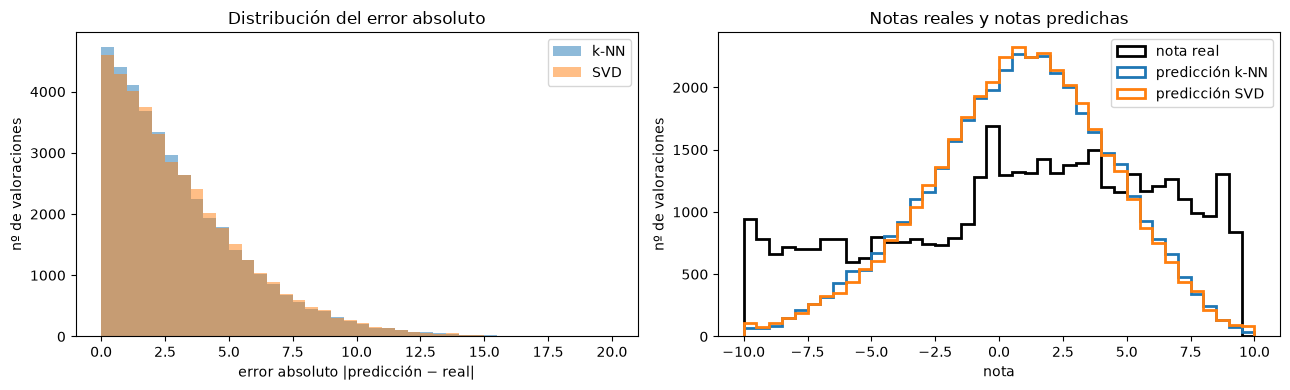

,error k-NN,error SVD
25 %,1.10,1.14
50 % (mediana),2.46,2.50
75 %,4.48,4.53
90 %,6.76,6.81


Desviación típica:  real = 5.30   pred_knn = 3.59   pred_svd = 3.57


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

# Izquierda: cuántas valoraciones tienen cada tamaño de error
tramos_error = np.linspace(0, 20, 41)                 # tramos de 0,5 puntos (el error máximo posible es 20)
ejes[0].hist(tabla["err_knn"], tramos_error, alpha=0.5, label="k-NN")
ejes[0].hist(tabla["err_svd"], tramos_error, alpha=0.5, label="SVD")
ejes[0].set_xlabel("error absoluto |predicción − real|")
ejes[0].set_ylabel("nº de valoraciones")
ejes[0].set_title("Distribución del error absoluto")
ejes[0].legend()

# Derecha: qué notas predice cada método, comparado con las notas reales
tramos_nota = np.linspace(-10, 10, 41)
ejes[1].hist(tabla["real"], tramos_nota, histtype="step", linewidth=2, color="black", label="nota real")
ejes[1].hist(tabla["pred_knn"], tramos_nota, histtype="step", linewidth=2, label="predicción k-NN")
ejes[1].hist(tabla["pred_svd"], tramos_nota, histtype="step", linewidth=2, label="predicción SVD")
ejes[1].set_xlabel("nota")
ejes[1].set_ylabel("nº de valoraciones")
ejes[1].set_title("Notas reales y notas predichas")
ejes[1].legend()
plt.tight_layout()
plt.show()

percentiles = tabla[["err_knn", "err_svd"]].quantile([0.25, 0.5, 0.75, 0.9])
percentiles.index = ["25 %", "50 % (mediana)", "75 %", "90 %"]
percentiles.columns = ["error k-NN", "error SVD"]
display(percentiles.round(2))

dispersion = tabla[["real", "pred_knn", "pred_svd"]].std()   # desviación típica: cuánto se alejan de su media
print("Desviación típica:  " + "   ".join(f"{nombre} = {valor:.2f}" for nombre, valor in dispersion.items()))

**Qué vemos:**

- Las dos distribuciones del error son casi iguales: la mitad de las predicciones fallan menos de unos 2,5 puntos, y
  k-NN tiene un error algo menor en todos los percentiles.
- Los dos métodos son **prudentes**: sus predicciones se alejan mucho menos de la media que las notas reales
  (desviación típica ≈ 3,6 frente a 5,3). Tiene sentido: cuando un método no está seguro, predecir cerca de la media
  es lo que menos arriesga. La consecuencia es que **ninguno de los dos se atreve a predecir notas extremas**.

### 3.2 Error según la nota real

,casos,mae_knn,mae_svd
tramo_nota,,,
"[-10, -5)",7310,4.974,5.071
"[-5, 0)",9238,2.554,2.576
"[0, 5)",13306,2.165,2.181
"[5, 10]",10146,3.567,3.625


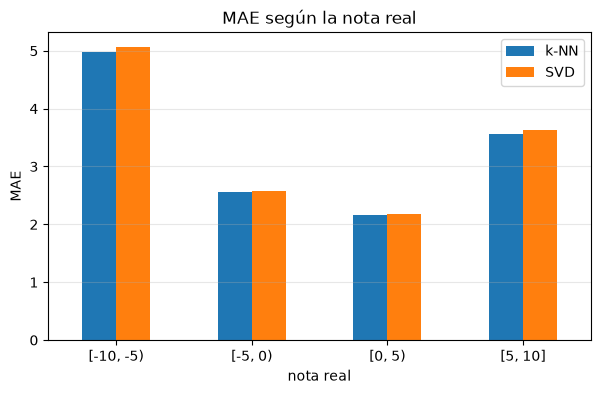

In [6]:
# Tramos de la nota real; el último incluye el 10 (por eso el borde superior es 10.01)
tabla["tramo_nota"] = pd.cut(tabla["real"], bins=[-10, -5, 0, 5, 10.01], right=False,
                             labels=["[-10, -5)", "[-5, 0)", "[0, 5)", "[5, 10]"])
por_nota = tabla.groupby("tramo_nota", observed=True).agg(
    casos=("real", "size"), mae_knn=("err_knn", "mean"), mae_svd=("err_svd", "mean"))
display(por_nota.round(3))
por_nota[["mae_knn", "mae_svd"]].plot.bar(figsize=(7, 4), rot=0)
plt.xlabel("nota real")
plt.ylabel("MAE")
plt.title("MAE según la nota real")
plt.legend(["k-NN", "SVD"])
plt.grid(alpha=0.3, axis="y")
plt.show()

**Qué vemos:** los dos métodos fallan mucho más en las **notas extremas**, sobre todo en las muy negativas (MAE
cercano a 5), que en las intermedias (algo más de 2). Es la otra cara de su prudencia: como no predicen notas
extremas, cuando la nota real es extrema el error es grande. k-NN es mejor en todos los tramos, y su ventaja es mayor
en los extremos.

### 3.3 Error según la actividad del usuario

¿Se equivocan más con los usuarios que han valorado pocos restaurantes? Contamos cuántas notas conocidas tiene cada
usuario en `recommendation_dataset.csv` (solo leemos el fichero para esto).

,casos,mae_knn,mae_svd
tramo_usuario,,,
menos de 25,2440,3.456,3.483
25 a 49,7861,3.235,3.312
50 a 74,12489,3.071,3.099
75 a 100,17210,3.064,3.104


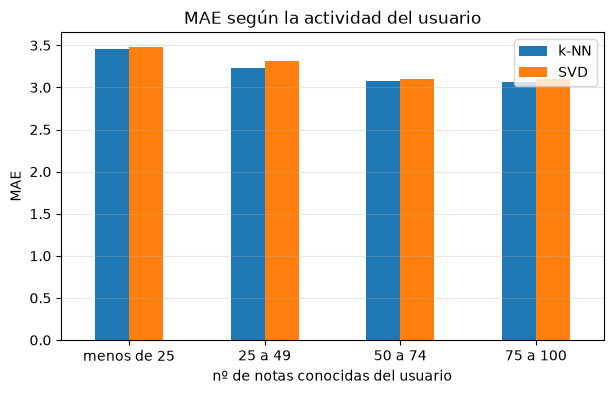

In [7]:
datos = pd.read_csv(f"{RUTA_DATOS}/recommendation_dataset.csv", sep=";", index_col=0)
notas_por_usuario = (datos != 99).sum(axis=1)          # nº de notas conocidas de cada usuario (99 = desconocida)
del datos                                              # ya no la necesitamos: liberamos la memoria

tabla["notas_usuario"] = tabla["usuario"].map(notas_por_usuario).to_numpy()
tabla["tramo_usuario"] = pd.cut(tabla["notas_usuario"], bins=[0, 25, 50, 75, 101], right=False,
                                labels=["menos de 25", "25 a 49", "50 a 74", "75 a 100"])
por_usuario = tabla.groupby("tramo_usuario", observed=True).agg(
    casos=("real", "size"), mae_knn=("err_knn", "mean"), mae_svd=("err_svd", "mean"))
display(por_usuario.round(3))
por_usuario[["mae_knn", "mae_svd"]].plot.bar(figsize=(7, 4), rot=0)
plt.xlabel("nº de notas conocidas del usuario")
plt.ylabel("MAE")
plt.title("MAE según la actividad del usuario")
plt.legend(["k-NN", "SVD"])
plt.grid(alpha=0.3, axis="y")
plt.show()

**Qué vemos:** los dos métodos se equivocan más con los usuarios que han valorado **pocos** restaurantes (de ellos
sabemos menos) y mejoran cuantas más notas tiene el usuario. k-NN es mejor en todos los tramos.

### 3.4 ¿Se parecen las predicciones de los dos métodos?

Correlación entre las predicciones de k-NN y SVD: 0.938
Diferencia media entre sus predicciones: 0.91 puntos
Acierta más k-NN: 51.6 %  |  acierta más SVD: 48.3 %  |  empate: 0.1 %


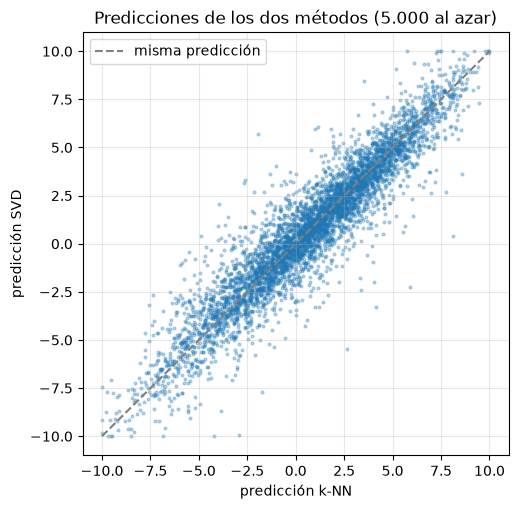

In [8]:
correlacion = float(np.corrcoef(tabla["pred_knn"], tabla["pred_svd"])[0, 1])
diferencia_media = float((tabla["pred_knn"] - tabla["pred_svd"]).abs().mean())
pct_gana_knn = float(100 * (tabla["err_knn"] < tabla["err_svd"]).mean())
pct_gana_svd = float(100 * (tabla["err_svd"] < tabla["err_knn"]).mean())
pct_empate = 100 - pct_gana_knn - pct_gana_svd
print(f"Correlación entre las predicciones de k-NN y SVD: {correlacion:.3f}")
print(f"Diferencia media entre sus predicciones: {diferencia_media:.2f} puntos")
print(f"Acierta más k-NN: {pct_gana_knn:.1f} %  |  acierta más SVD: {pct_gana_svd:.1f} %  |  empate: {pct_empate:.1f} %")

# Dispersión de 5.000 valoraciones elegidas al azar (con las 40.000 la nube se vería como una mancha)
muestra = tabla.sample(5000, random_state=SEMILLA)
plt.figure(figsize=(5.5, 5.5))
plt.scatter(muestra["pred_knn"], muestra["pred_svd"], s=4, alpha=0.3)
plt.plot([-10, 10], [-10, 10], color="gray", linestyle="--", label="misma predicción")
plt.xlabel("predicción k-NN")
plt.ylabel("predicción SVD")
plt.title("Predicciones de los dos métodos (5.000 al azar)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Qué vemos:** las predicciones de los dos métodos se parecen mucho (correlación ≈ 0,94), pero no son iguales: de
media difieren casi un punto y, valoración a valoración, cada método acierta más en aproximadamente la mitad de los
casos (k-NN, en algo más de la mitad). Es decir, k-NN gana por poco y de forma repartida: no es que la SVD falle
mucho en unos pocos casos, sino que falla un poco más en general.

## 4. Diferencias de funcionamiento

Los dos métodos parten de la **misma base** (los sesgos $\mu + b_u + b_i$) y trabajan sobre los mismos **residuos**
(lo que los sesgos no explican). Se diferencian en cómo usan esos residuos:

| | **k-NN por ítems** | **SVD truncada** |
|---|---|---|
| **Idea** | La nota de $u$ en $i$ se parece a las que $u$ puso a restaurantes **parecidos** a $i$ | Los gustos de todos los usuarios se resumen en $f$ **ejes de gusto**; usuario y restaurante se sitúan en esos ejes |
| **Tipo** | Basado en **memoria**: predice consultando directamente las notas del usuario | Basado en **modelo**: aprende un resumen de los datos (los ejes) y predice con él |
| **Qué aprende** | Una matriz de similitudes 100 × 100 entre restaurantes | Una matriz $V_f$ de 100 × $f$ (los ejes) |
| **Hiperparámetro** | $k$: número de vecinos | $f$: número de ejes |
| **Huecos** | Los ignora: solo usa restaurantes que el usuario ha valorado | Los trata como residuo 0 ("lo que dicen los sesgos") |
| **Qué hay que calcular** | Las similitudes (una vez) y, para cada predicción, buscar los $k$ vecinos | Una SVD (una vez) y, para cada predicción, un producto de $f$ números |
| **Cómo se explica una predicción** | Fácil: "porque te gustaron estos restaurantes parecidos" | Difícil: los ejes salen de los datos y no tienen un significado claro |

En los dos casos, $k$ y $f$ se eligieron con la validación, cada uno en su notebook.

## 5. Conclusión

- **Gana k-NN por ítems**, en validación y en el test oficial (unas 4–5 centésimas de MAE). Por eso la entrega
  (`resultats.csv`) se hace con k-NN.
- La ventaja es **pequeña pero constante**: k-NN tiene menos error en todos los percentiles, en todos los tramos de nota
  real y en todos los tramos de actividad del usuario.
- Los dos métodos comparten las mismas debilidades: son prudentes (predicen notas menos extremas que las reales), así
  que fallan sobre todo en las valoraciones extremas, y se equivocan más con los usuarios que tienen pocas notas.
- Sus predicciones se parecen mucho, pero no son idénticas: no aprenden exactamente lo mismo de los datos.

La celda siguiente comprueba con `assert` cada una de estas afirmaciones (y las de los apartados anteriores).

In [9]:
# Comprobaciones de lo que dicen los textos de este notebook
assert mae_val["k-NN ítems"] < mae_val["SVD"] and mae_ofi["k-NN ítems"] < mae_ofi["SVD"]          # gana k-NN
assert 0.03 < precision.loc["Diferencia (SVD − k-NN)"].min() and precision.loc["Diferencia (SVD − k-NN)"].max() < 0.06
assert (percentiles["error k-NN"] < percentiles["error SVD"]).all()                               # todos los percentiles
assert dispersion["pred_knn"] < 0.75 * dispersion["real"] and dispersion["pred_svd"] < 0.75 * dispersion["real"]
assert (por_nota["mae_knn"] < por_nota["mae_svd"]).all()                                          # todos los tramos de nota
extremos, centro = por_nota.iloc[[0, 3]], por_nota.iloc[[1, 2]]
assert extremos[["mae_knn", "mae_svd"]].values.min() > centro[["mae_knn", "mae_svd"]].values.max()  # fallan más en extremos
ventaja = por_nota["mae_svd"] - por_nota["mae_knn"]
assert ventaja.iloc[[0, 3]].min() > ventaja.iloc[[1, 2]].max()                                   # ventaja mayor en extremos
assert (por_usuario["mae_knn"] < por_usuario["mae_svd"]).all()                                    # todos los tramos de usuario
assert (por_usuario.iloc[0][["mae_knn", "mae_svd"]] > por_usuario.iloc[-1][["mae_knn", "mae_svd"]]).all()  # pocos > muchos
assert correlacion > 0.9 and 0.8 < diferencia_media < 1
assert 50 < pct_gana_knn < 55 and 45 < pct_gana_svd < 50
print("Todas las afirmaciones de los textos se cumplen")

Todas las afirmaciones de los textos se cumplen
